# Data mining 


In [38]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from wordcloud import WordCloud


In [3]:
df = pd.read_json('top_books.json', lines=True)

In [ ]:
df.head()

In [5]:
df.columns

Index(['id', 'like_count', 'region_code', 'video_description',
       'favorites_count', 'hashtag_names', 'effect_ids', 'is_stem_verified',
       'playlist_id', 'username', 'video_duration', 'video_label',
       'comment_count', 'create_time', 'music_id', 'view_count',
       'video_mention_list', 'voice_to_text', 'hashtag_info_list',
       'share_count', 'sticker_info_list', 'effect_info_list', 'video_tag',
       'full_text', 'book_title'],
      dtype='object')

In [20]:
print(f"Sample size: {len(df)}")

Sample size: 51270


In [7]:
missing_info = pd.DataFrame(
    {
        "Type": df.dtypes,
        "Null": df.isnull().sum(),
        "% Null": (df.isnull().sum() / len(df) * 100).round(2),
    }
)
print(missing_info)

                              Type   Null  % Null
id                           int64      0    0.00
like_count                   int64      0    0.00
region_code                 object      0    0.00
video_description           object      0    0.00
favorites_count              int64      0    0.00
hashtag_names               object      0    0.00
effect_ids                  object      0    0.00
is_stem_verified              bool      0    0.00
playlist_id                  int64      0    0.00
username                    object      0    0.00
video_duration               int64      0    0.00
video_label                 object      0    0.00
comment_count                int64      0    0.00
create_time         datetime64[ns]      0    0.00
music_id                     int64      0    0.00
view_count                   int64      0    0.00
video_mention_list          object      0    0.00
voice_to_text               object      0    0.00
hashtag_info_list           object      0    0.00


In [21]:
num_cols = [
    "view_count",
    "like_count",
    "comment_count",
    "share_count",
    "favorites_count",
    "video_duration",
]
stats = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T
print(stats.round(2))

                    mean  median       std  min        max
view_count       3480.90   800.0  26577.41  0.0  2704824.0
like_count        325.35    57.0   2924.54  0.0   271394.0
comment_count       6.67     2.0     44.54  0.0     3272.0
share_count        22.12     1.0    363.74  0.0    53779.0
favorites_count    49.68     6.0    386.53  0.0    30888.0
video_duration     22.74    11.0     58.57  0.0     2319.0


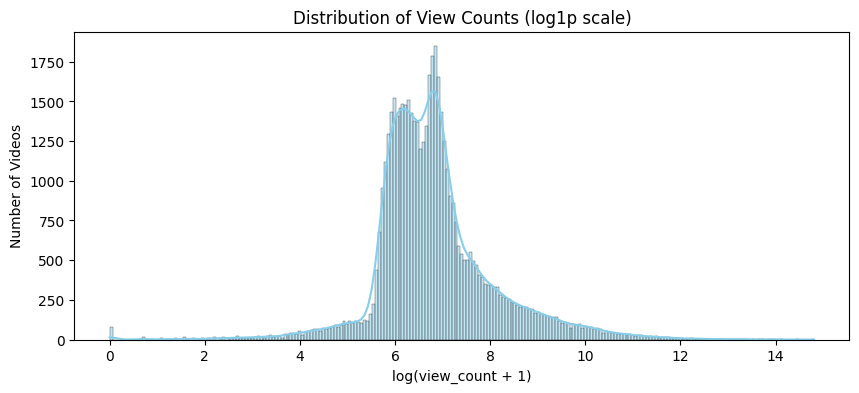

In [10]:
#View counts can vary widely, so we will visualize the distribution of view counts using a logarithmic scale to better understand the data.
plt.figure(figsize=(10, 4))
sns.histplot(np.log1p(df["view_count"]), kde=True, color="skyblue")
plt.title("Distribution of View Counts (log1p scale)")
plt.xlabel("log(view_count + 1)")
plt.ylabel("Number of Videos")
plt.show()

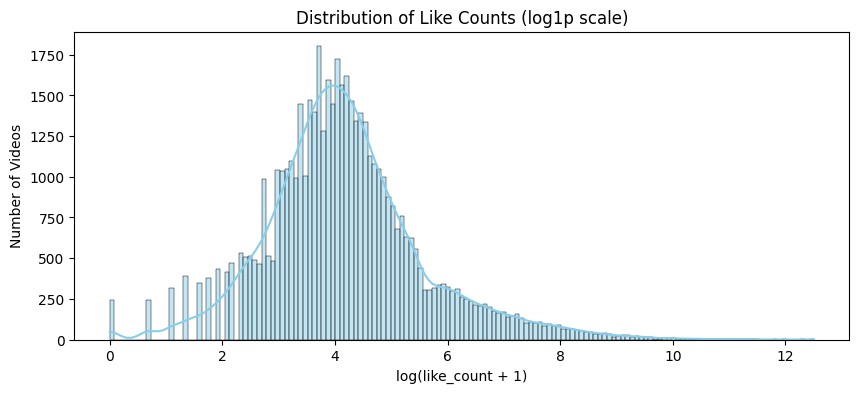

In [24]:
plt.figure(figsize=(10, 4))
sns.histplot(np.log1p(df["like_count"]), kde=True, color="skyblue")
plt.title("Distribution of Like Counts (log1p scale)")
plt.xlabel("log(like_count + 1)")
plt.ylabel("Number of Videos")
plt.show()

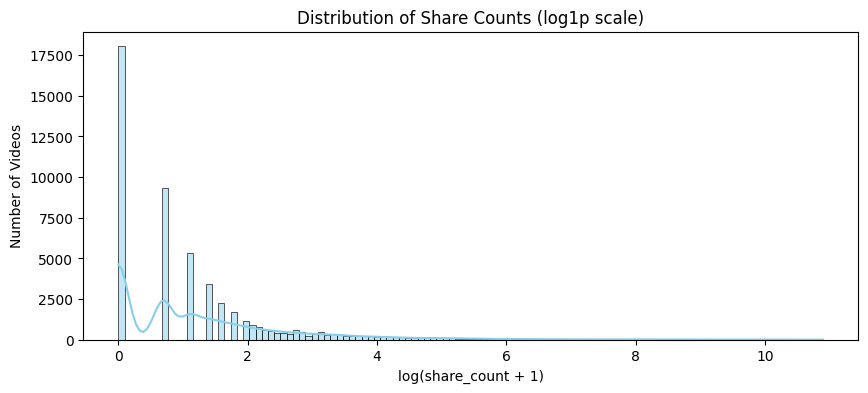

In [17]:
plt.figure(figsize=(10, 4))
sns.histplot(np.log1p(df["share_count"]), kde=True, color="skyblue")
plt.title("Distribution of Share Counts (log1p scale)")
plt.xlabel("log(share_count + 1)")
plt.ylabel("Number of Videos")
plt.show()

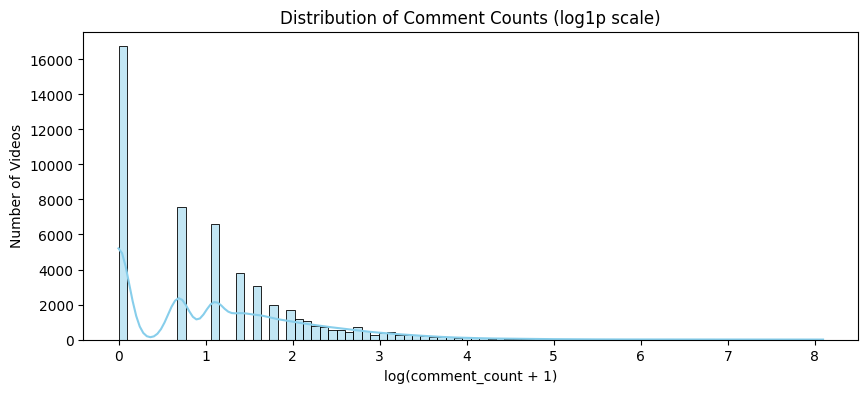

In [18]:
plt.figure(figsize=(10, 4))
sns.histplot(np.log1p(df["comment_count"]), kde=True, color="skyblue")
plt.title("Distribution of Comment Counts (log1p scale)")
plt.xlabel("log(comment_count + 1)")
plt.ylabel("Number of Videos")
plt.show()

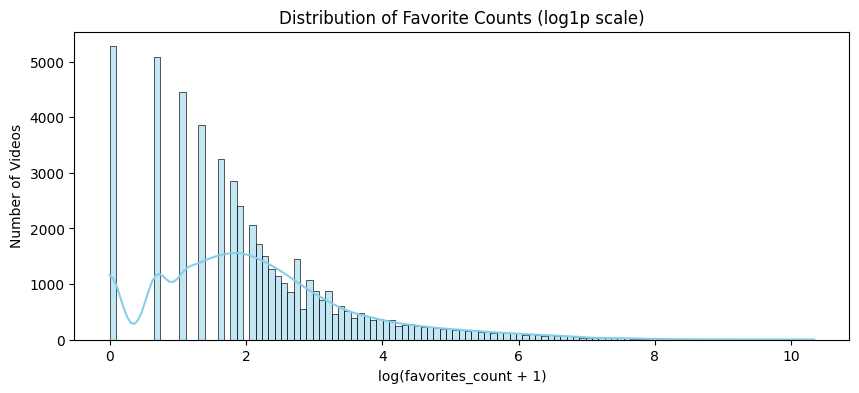

In [28]:
plt.figure(figsize=(10, 4))
sns.histplot(np.log1p(df["favorites_count"]), kde=True, color="skyblue")
plt.title("Distribution of Favorite Counts (log1p scale)")
plt.xlabel("log(favorites_count + 1)")
plt.ylabel("Number of Videos")
plt.show()

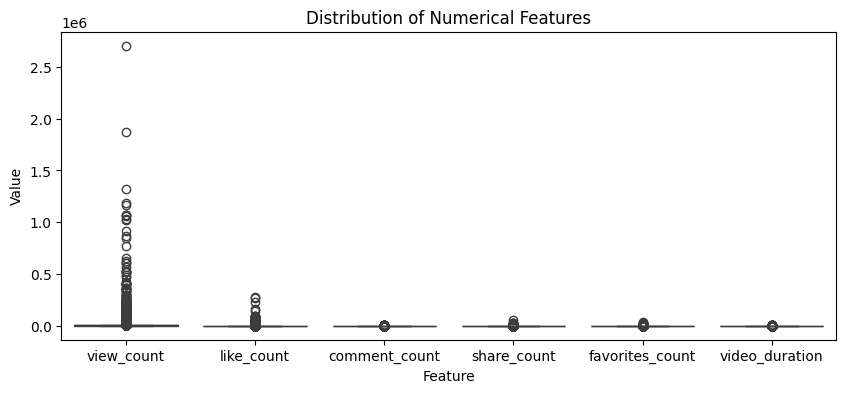

In [25]:
#boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[num_cols])
plt.title("Distribution of Numerical Features")
plt.ylabel("Value")
plt.xlabel("Feature")
plt.show()

Text(0.5, 1.0, 'Correlation Heatmap of Numerical Features')

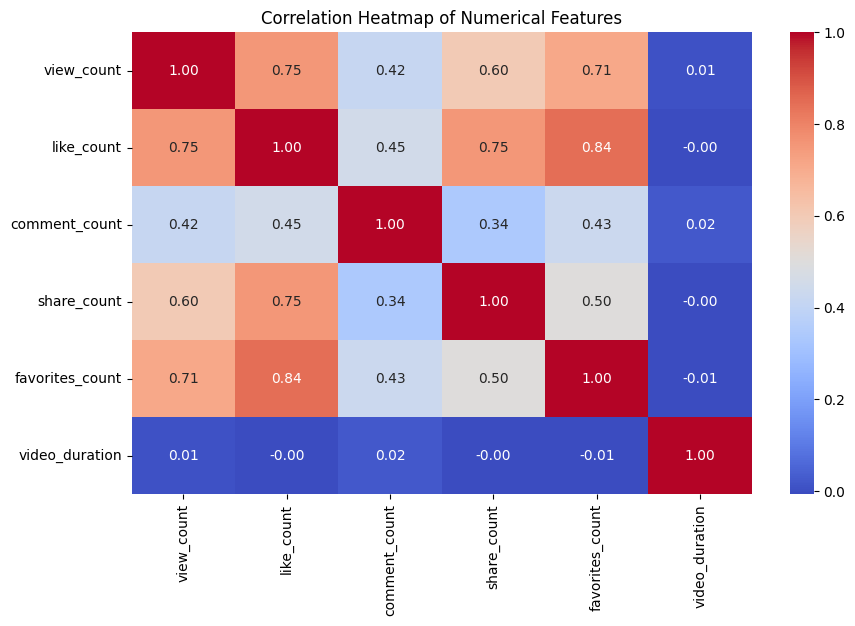

In [29]:
# heatmap of correlations between numerical features
plt.figure(figsize=(10, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")

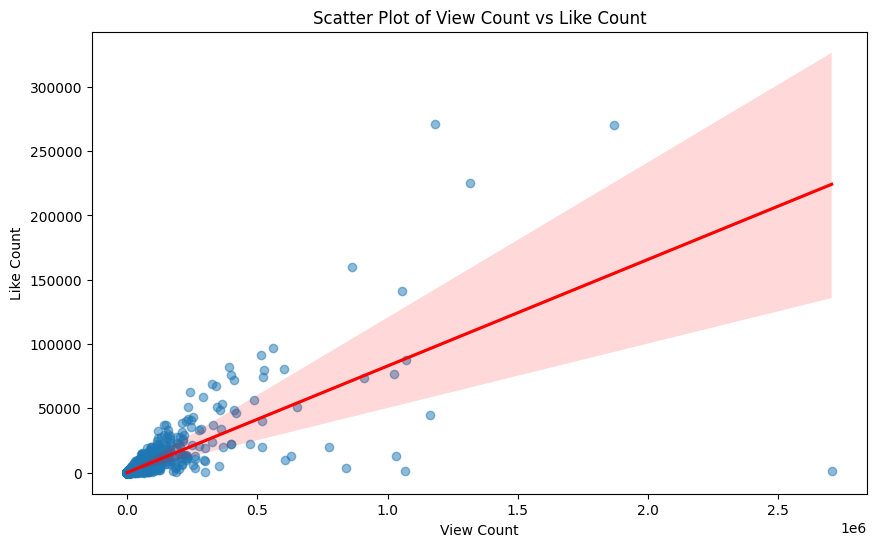

In [30]:
# Scatter Plot with a Regression Line - like_count vs view_count
plt.figure(figsize=(10, 6))
sns.regplot(x="view_count", y="like_count", data=df, scatter_kws={"alpha":0.5}, line_kws={"color":"red"})
plt.title("Scatter Plot of View Count vs Like Count")
plt.xlabel("View Count")
plt.ylabel("Like Count")
plt.show()

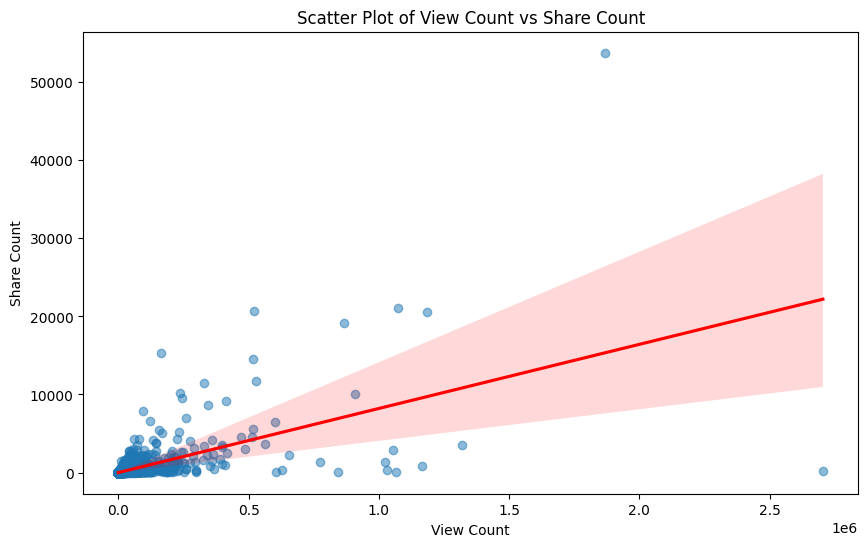

In [32]:
# Scatter Plot with a Regression Line - share_count vs view_count
plt.figure(figsize=(10, 6))
sns.regplot(x="view_count", y="share_count", data=df, scatter_kws={"alpha":0.5}, line_kws={"color":"red"})
plt.title("Scatter Plot of View Count vs Share Count")
plt.xlabel("View Count")
plt.ylabel("Share Count")
plt.show()

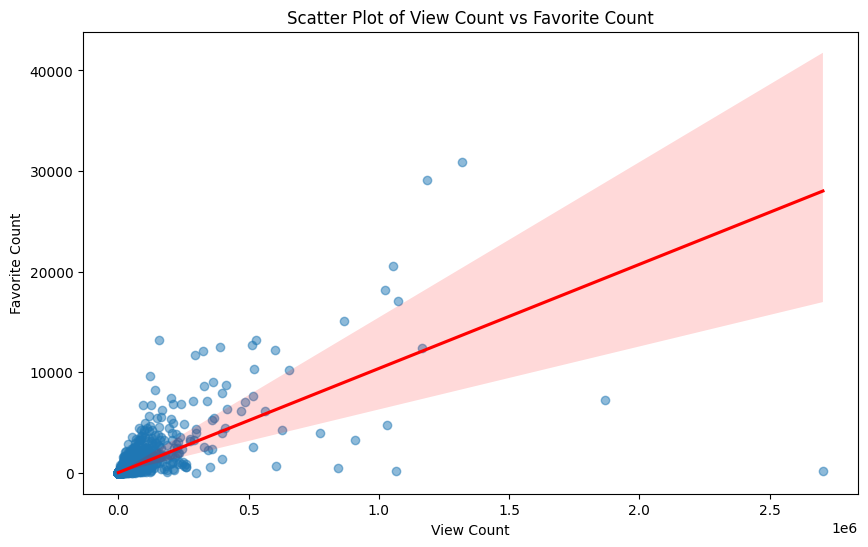

In [33]:
# Scatter Plot with a Regression Line - favorites_count vs view_count
plt.figure(figsize=(10, 6))
sns.regplot(x="view_count", y="favorites_count", data=df, scatter_kws={"alpha":0.5}, line_kws={"color":"red"})
plt.title("Scatter Plot of View Count vs Favorite Count")
plt.xlabel("View Count")
plt.ylabel("Favorite Count")
plt.show()

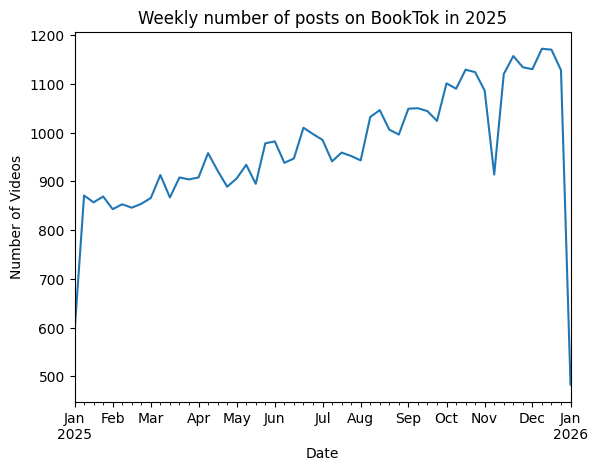

In [19]:
# Time series analysis of post counts over time
# Aggregation of data for daily/weekly analysis
df['create_time'] = pd.to_datetime(df['create_time'], unit='s')
df.set_index('create_time').resample('W')['id'].count().plot(
    title='Weekly number of posts on BookTok in 2025'
)
plt.xlabel('Date')
plt.ylabel('Number of Videos')
plt.show()


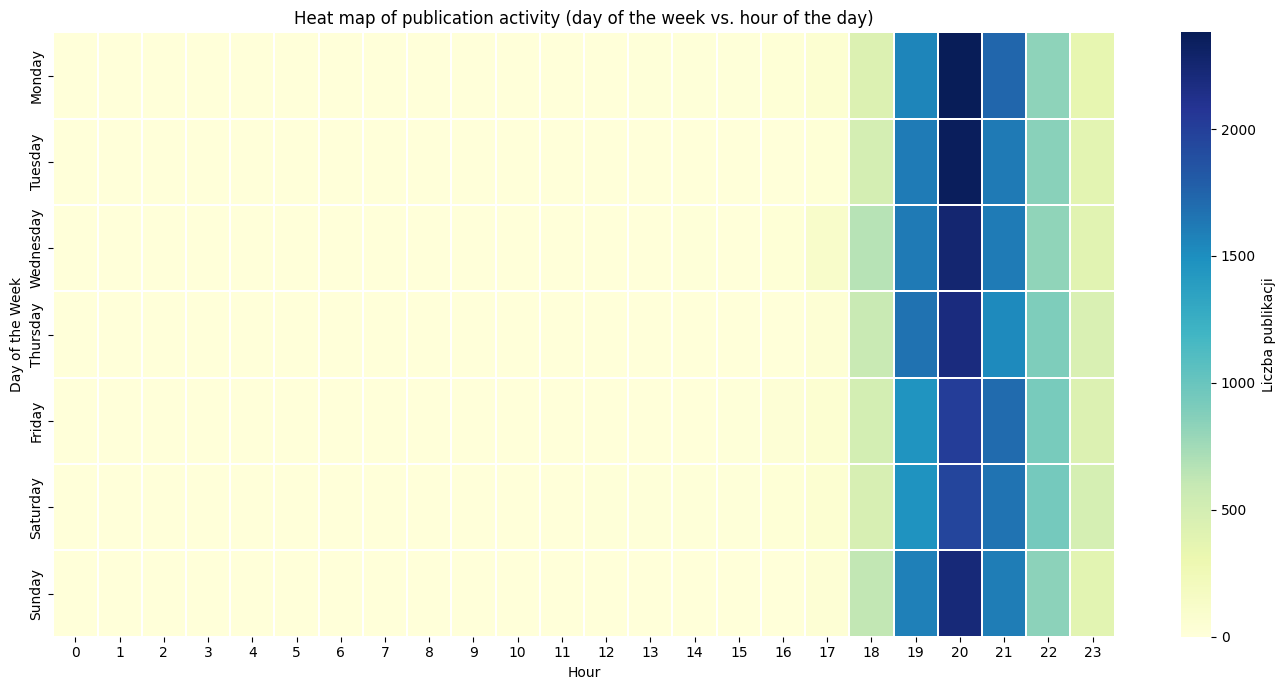

In [34]:
# (Publishing Activity Heatmap

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

activity = (
    df.assign(
        day=df["create_time"].dt.day_name(),
        hour=df["create_time"].dt.hour
    )
    .groupby(["day", "hour"], observed=False)
    .size()
    .unstack(fill_value=0)
    .reindex(day_order)
    .reindex(range(24), axis=1, fill_value=0)
)

plt.figure(figsize=(14, 7))
sns.heatmap(
    activity,
    cmap="YlGnBu",
    annot=False,
    fmt="d",
    linewidths=0.3,
    cbar_kws={"label": "Liczba publikacji"},
    xticklabels=range(24),
    yticklabels=day_order
)
plt.title("Heat map of publication activity (day of the week vs. hour of the day)")
plt.xlabel("Hour")
plt.ylabel("Day of the Week")
plt.tight_layout()
plt.show()

In [12]:
# chceck region
print(df["region_code"].value_counts().head(5))

region_code
PL    25699
pl    25571
Name: count, dtype: int64


In [13]:
#unique values 
print(f"Number of unique creators (username): {df['username'].nunique()}")
print(f"Number of unique music tracks (music_id): {df['music_id'].nunique()}")

Number of unique creators (username): 9016
Number of unique music tracks (music_id): 29505


In [16]:
# text length analysis
df["desc_len"] = df["video_description"].fillna("").apply(len)
df["speech_len"] = df["voice_to_text"].fillna("").apply(len)
print(f"Description (characters): {df['desc_len'].mean():.1f}")
print(f"Voice Transcription (characters): {df['speech_len'].mean():.1f}")

Description (characters): 178.9
Voice Transcription (characters): 67.3


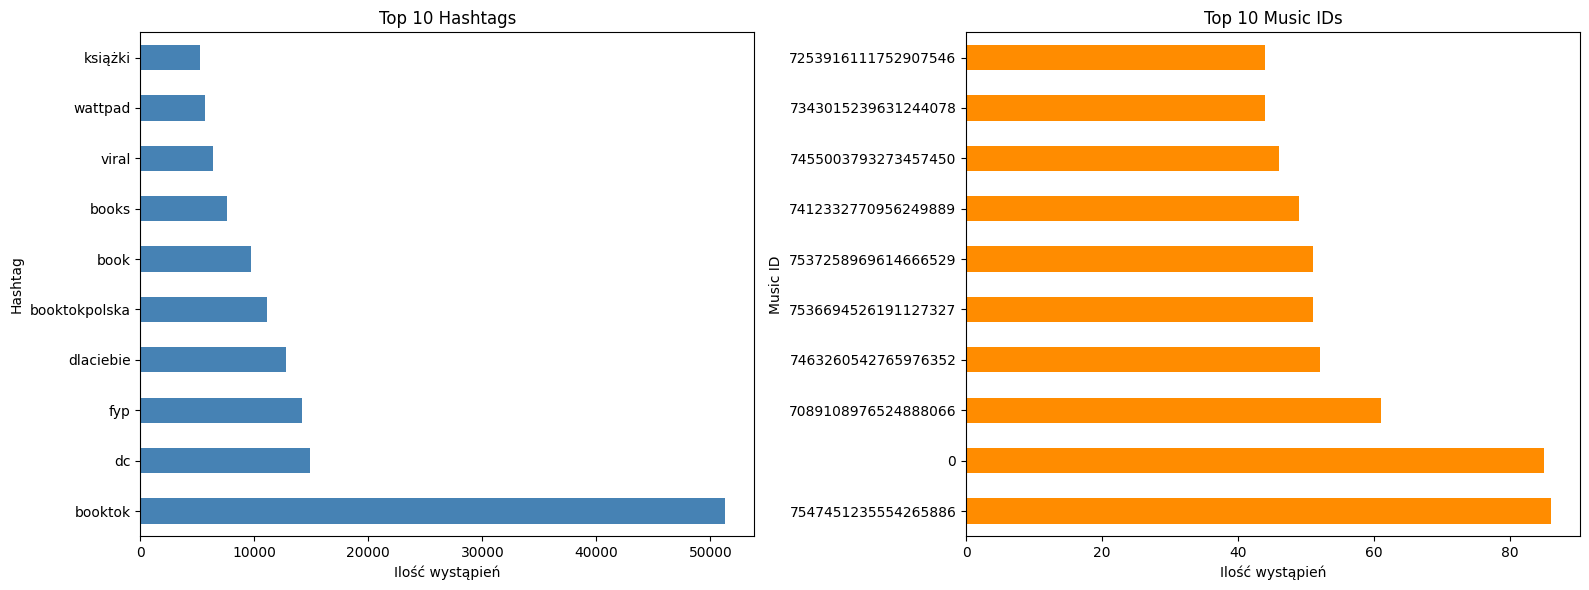

In [35]:
# Top Hashtags / Music

top_n = 10
top_hashtags = (
    df["hashtag_names"]
    .dropna()
    .explode()
    .str.lower()
    .value_counts()
    .head(top_n)
    .sort_values()
)

# Top music IDs
top_music = (
    df["music_id"]
    .value_counts()
    .head(top_n)
    .sort_values()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Hashtags
top_hashtags.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title(f"Top {top_n} Hashtags")
axes[0].set_xlabel("Ilość wystąpień")
axes[0].set_ylabel("Hashtag")
axes[0].invert_yaxis()

# Music
top_music.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title(f"Top {top_n} Music IDs")
axes[1].set_xlabel("Ilość wystąpień")
axes[1].set_ylabel("Music ID")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

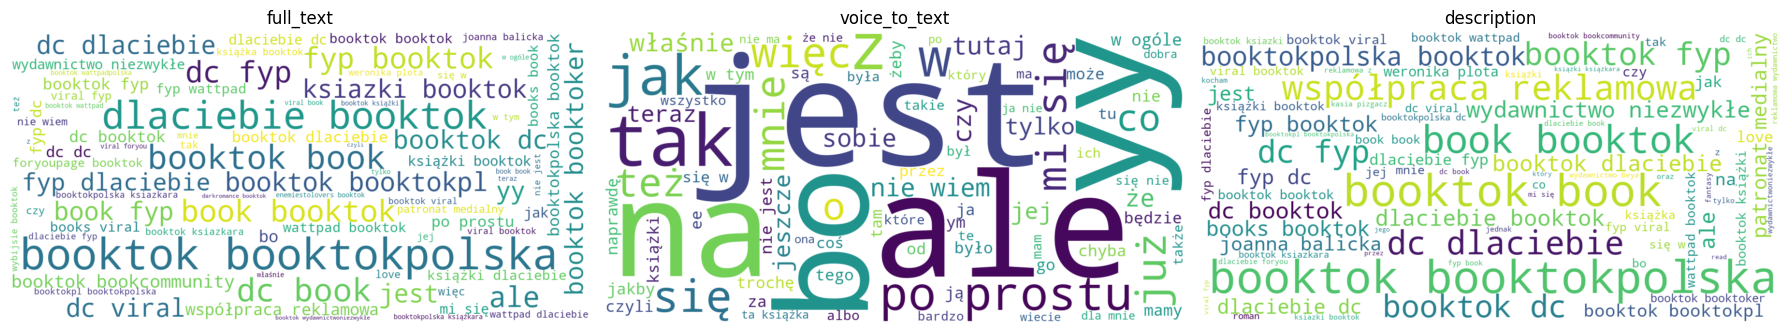

In [39]:

description_col = "description" if "description" in df.columns else "video_description"

text_sources = {
    "full_text": df["full_text"].fillna("").astype(str),
    "voice_to_text": df["voice_to_text"].fillna("").astype(str),
    "description": df[description_col].fillna("").astype(str),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, series) in zip(axes, text_sources.items()):
    text = " ".join(series.str.lower())
    wc = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        max_words=80,
        colormap="viridis"
    ).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(name)

plt.tight_layout()
plt.show()